In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the datasets
sales = pd.read_csv("../data/processed/online_retail_cleaned.csv", parse_dates=["InvoiceDate"])
returns = pd.read_csv("../data/processed/online_retail_returns.csv", parse_dates=["InvoiceDate"])

In [3]:
# 1) Number of rows, invoices, and identified customers
identified = sales[sales["CustomerID"] != -1]
print("Rows:", f"{len(sales):,}")
print("Invoices:", f"{sales['InvoiceNo'].nunique():,}")
print("Identified customers:", f"{identified['CustomerID'].nunique():,}")

# 2) Proportion of rows and revenue from unidentified customers (CustomerID == -1)
no_id = sales["CustomerID"] == -1
print(f"CustomerID == -1: {no_id.mean():.1%} of rows, "
      f"{sales.loc[no_id, 'TotalPrice'].sum() / sales['TotalPrice'].sum():.1%} of revenue")

# 3) date range of the dataset
print("Date range:", sales["InvoiceDate"].min(), "->", sales["InvoiceDate"].max())

# 4) largest sales by TotalPrice
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate", "TotalPrice"]
print(sales.nlargest(5, "TotalPrice")[cols])

# 5) Combine returns: C-invoices vs. non-C invoices
returns["IsCInvoice"] = returns["InvoiceNo"].astype(str).str.startswith("C")
print(returns["IsCInvoice"].value_counts())

Rows: 522,537
Invoices: 19,773
Identified customers: 4,334
CustomerID == -1: 25.1% of rows, 14.7% of revenue
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
        InvoiceNo StockCode                          Description  Quantity  \
521070     581483     23843          PAPER CRAFT , LITTLE BIRDIE     80995   
59407      541431     23166       MEDIUM CERAMIC TOP STORAGE JAR     74215   
214408     556444     22502       PICNIC BASKET WICKER 60 PIECES        60   
335866     567423     23243  SET OF TEA COFFEE SUGAR TINS PANTRY      1412   
50697      540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   

        UnitPrice  CustomerID         InvoiceDate  TotalPrice  
521070       2.08       16446 2011-12-09 09:15:00   168469.60  
59407        1.04       12346 2011-01-18 10:01:00    77183.60  
214408     649.50       15098 2011-06-10 15:28:00    38970.00  
335866       5.06       17450 2011-09-20 11:05:00     7144.72  
50697        2.10       15749 2011-01-11 12:55:

In [4]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate", "TotalPrice"]

# 1) Largest rows of returns: Is there a pair of suspicious three rows there?
print(returns.nsmallest(5, "TotalPrice")[cols])

# 2) what are 474 rows without C?
non_c = returns[~returns["IsCInvoice"]]
print("Share with UnitPrice == 0:", (non_c["UnitPrice"] == 0).mean().round(3))
print("Share with CustomerID == -1:", (non_c["CustomerID"] == -1).mean().round(3))
print(non_c["StockCode"].value_counts().head(5))

# 3) Product vs. non-product returns (following the same Step 5 pattern)
is_product = returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)")
print(returns.groupby(is_product)["TotalPrice"].agg(["count", "sum"]))

     InvoiceNo  StockCode                     Description  Quantity  \
9718   C581484      23843     PAPER CRAFT , LITTLE BIRDIE    -80995   
1045   C541433      23166  MEDIUM CERAMIC TOP STORAGE JAR    -74215   
4143   C556445          M                          Manual        -1   
9484   C580605  AMAZONFEE                      AMAZON FEE        -1   
744    C540117  AMAZONFEE                      AMAZON FEE        -1   

      UnitPrice  CustomerID         InvoiceDate  TotalPrice  
9718       2.08       16446 2011-12-09 09:27:00  -168469.60  
1045       1.04       12346 2011-01-18 10:17:00   -77183.60  
4143   38970.00       15098 2011-06-10 15:31:00   -38970.00  
9484   17836.46          -1 2011-12-05 11:36:00   -17836.46  
744    16888.02          -1 2011-01-05 09:55:00   -16888.02  
Share with UnitPrice == 0: 1.0
Share with CustomerID == -1: 1.0
StockCode
85175     5
85172     4
21830     4
72802C    4
22423     3
Name: count, dtype: int64
           count        sum
StockCode    

## Analysis-ready data

In [5]:
# Convert CustomerID to nullable integer type
sales['CustomerID'] = sales['CustomerID'].astype('Int64').mask(sales['CustomerID'] == -1, pd.NA)

In [6]:
# Invoices that were fully reversed by a cancellation invoice within minutes.
# Evidence: each has a matching "C" invoice with the same CustomerID and the same
# total amount (168,469.60 / 77,183.60 / 38,970.00), issued 3-16 minutes later.
# Note: for 556444 the cancellation is a manual line (StockCode "M", Quantity -1),
# so it matches by amount, not by product or quantity.
# Assumption (not proven): these are data-entry corrections, not real customer returns.
# Found by inspecting the largest sales lines; no general matching was attempted.
REVERSED_INVOICES = [581483, 541431, 556444]

sales["IsReversedOrder"] = sales["InvoiceNo"].isin(REVERSED_INVOICES)

# value counts and total revenue of reversed orders
sales.groupby("IsReversedOrder")["TotalPrice"].agg(["count", "sum"])

,count,sum
IsReversedOrder,,
False,522534,9962596.12
True,3,284623.20


In [7]:
# Replace 'EIRE' with 'Ireland' in the Country column
returns['Country'] = returns['Country'].replace('EIRE', 'Ireland')

In [8]:
# Categorize return types based on StockCode and IsCInvoice
cond_product_cancel = returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)") & returns["IsCInvoice"]
cond_non_product_cancel = ~returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)") & returns["IsCInvoice"]

conditions = [cond_product_cancel,
               cond_non_product_cancel]

choices = ["product_cancellation",
           "non_product_cancellation"]

returns["ReturnType"] = np.select(conditions, choices, default="stock_adjustment")

In [9]:
returns.groupby("ReturnType")["TotalPrice"].agg(["count", "sum"])

,count,sum
ReturnType,,
non_product_cancellation,583,-418078.57
product_cancellation,8668,-475901.16
stock_adjustment,474,0.00


# Phase 2: Sales Trends Over Time

**Business question:** How do revenue, order volume, and average order value change over time, and when are the peak and slow periods?

## KPI definitions

| KPI | Definition |
|---|---|
| Revenue | Sum of `TotalPrice` over product lines in the sales data (excludes shipping, fees, and manual entries) |
| Orders | Number of distinct `InvoiceNo` (an invoice is one order; a row is only one product line) |
| Average order value (AOV) | Revenue ÷ Orders |

## Scope and caveats

- Three invoices flagged `IsReversedOrder` (about 2.8% of revenue) are excluded from trend figures, because each was cancelled within minutes by a matching "C" invoice.
- The data ends on 2011-12-09, so **December 2011 is a partial month** and must not be compared directly with December 2010.
- Cancellations and returns are not netted against sales here. They are analyzed separately in the returns section.
- Findings describe patterns in this dataset only. Seasonality is based on a single year, so it cannot be separated from one-off effects.

## Plan

1. Monthly revenue, orders, and AOV
2. Weekday and hour-of-day patterns
3. Short summary for a non-technical reader

In [10]:
# 1. Filtering rows where the order is not cancelled, and creating a 'Month' column
sales_filtered = sales[~sales["IsReversedOrder"]].copy()
sales_filtered['Month'] = sales_filtered['InvoiceDate'].dt.to_period('M')

# 2. Grouping by 'Month' and calculating revenue and number of orders
monthly_summary = sales_filtered.groupby('Month').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reset_index()

# Calculating Average Order Value (AOV)
monthly_summary['AOV'] = monthly_summary['Revenue'] / monthly_summary['Orders']

monthly_summary

,Month,Revenue,Orders,AOV
0,2010-12,775638.36,1550,500.411845
1,2011-01,593196.64,1080,549.256148
2,2011-02,507799.87,1093,464.592745
3,2011-03,689833.51,1440,479.051049
4,2011-04,515377.99,1235,417.310113
5,2011-05,739953.00,1668,443.616906
6,2011-06,698588.98,1524,458.391719
7,2011-07,688219.34,1452,473.980262
8,2011-08,724216.50,1339,540.863704
9,2011-09,1028320.38,1818,565.632772


In [11]:
# convert Month column to string (so that matplotlib can display it)
months = monthly_summary['Month'] = monthly_summary['Month'].astype(str)
revenue = monthly_summary['Revenue']
aov = monthly_summary['AOV']

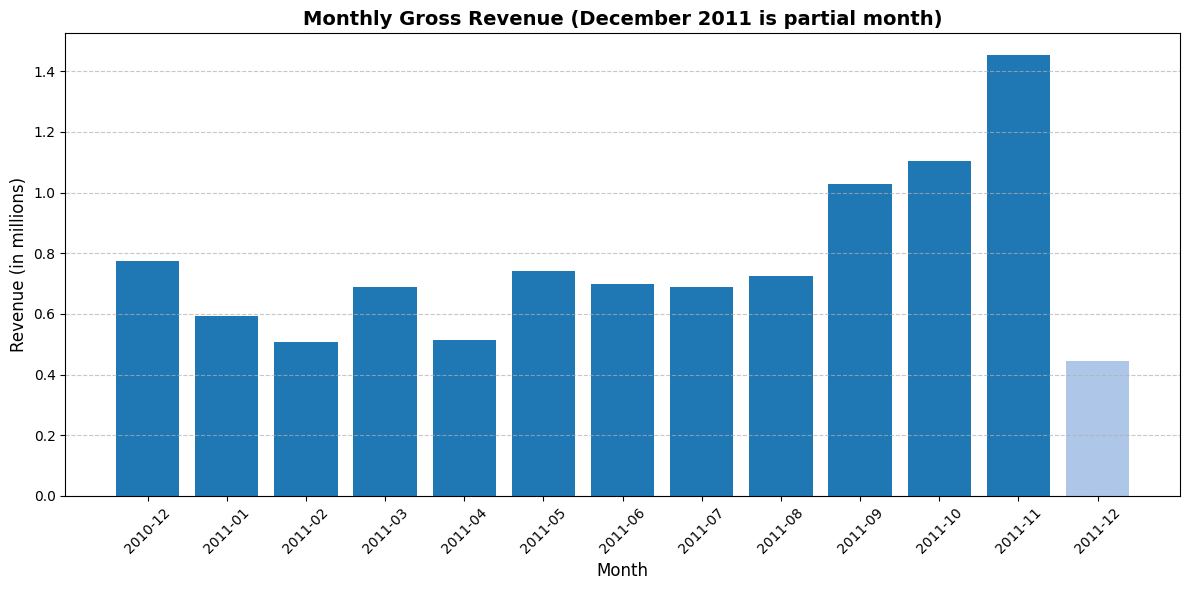

In [12]:
# make color list: all months are blue except last month (December 2011) gray or lighter
colors = ['#1f77b4'] * (len(monthly_summary) - 1) + ['#aec7e8']

plt.figure(figsize=(12, 6))
plt.bar(months, revenue/ 1e6, color=colors)

plt.title('Monthly Gross Revenue (December 2011 is partial month)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue (in millions)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Revenue was relatively flat from January to August 2011, at roughly 0.5–0.75M per month, then rose sharply: 1.03M in September, 1.10M in October, and 1.45M in November, about twice August’s level. This is consistent with year-end gift-season buying, but with only one year of data we cannot separate seasonality from one-off effects. December 2011 (light bar) covers only nine days and should not be read as a decline.

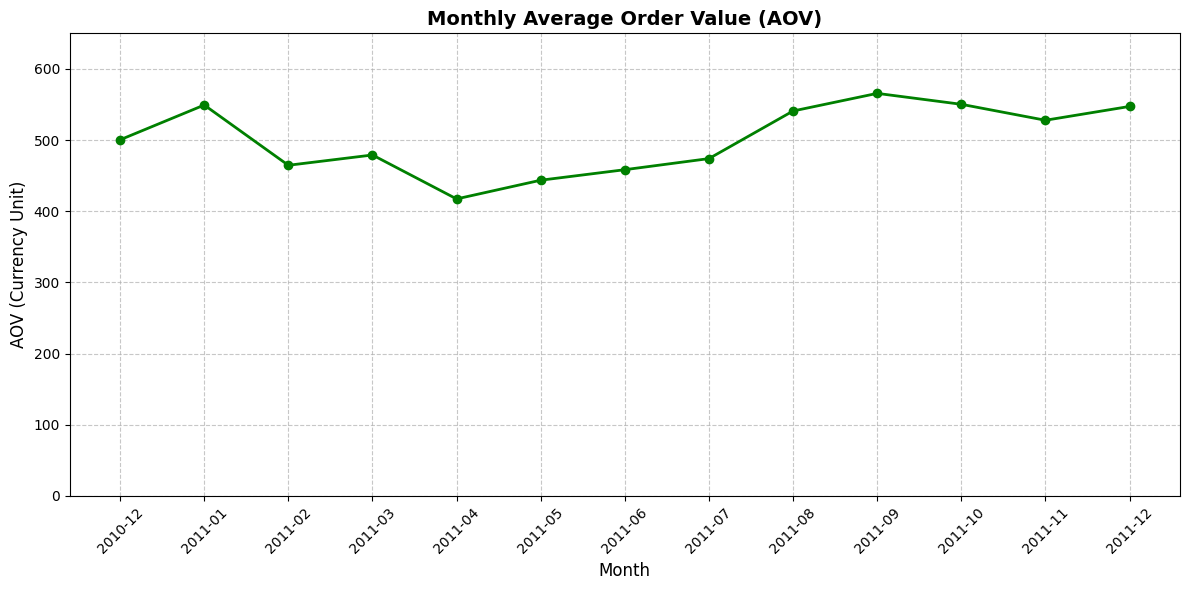

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(months, aov, marker='o', color='green', linewidth=2, markersize=6)

plt.title('Monthly Average Order Value (AOV)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('AOV (Currency Unit)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0, 650)

plt.tight_layout()
plt.show()

Average order value (AOV) fell from about 549 in January to a low of 417 in April, then recovered to a peak of 566 in September (+36% from the April low), and stayed between 528 and 550 afterwards. Because revenue = orders × AOV, the September–November revenue surge came mainly from more orders, not larger ones: AOV in November (528) was slightly below August (541), while orders roughly doubled (1,339 to 2,751). AOV is a mean, so we cannot tell whether its changes come from more items per order, higher-priced items, or a few very large orders; that needs a breakdown by order size.

In [14]:
monthly_summary[["Revenue", "Orders", "AOV"]].pct_change()

,Revenue,Orders,AOV
0,NaN,NaN,NaN
1,-0.235215,-0.303226,0.097608
2,-0.143960,0.012037,-0.154142
3,0.358475,0.317475,0.031120
4,-0.252895,-0.142361,-0.128882
5,0.435748,0.350607,0.063039
6,-0.055901,-0.086331,0.033305
7,-0.014844,-0.047244,0.034007
8,0.052305,-0.077824,0.141110
9,0.419907,0.357730,0.045795


In 9 of the 11 full month-over-month comparisons, revenue moved in the same direction as the number of orders. The exceptions were February, when AOV fell 15% while orders stayed flat (revenue down), and August, when AOV rose 14% while orders fell 8% (revenue up slightly). Orders are far more volatile than AOV (average absolute monthly change of about 20% versus 7%), so most revenue swings in this data come from order volume. With only one year of data we cannot tell whether this pattern is typical, and we do not know what caused the two exceptions.

## 2.2 Weekday and Hour-of-Day Patterns

**Business question:** On which days and at which hours do orders and revenue concentrate?

- Metrics: orders (distinct `InvoiceNo`) and revenue (sum of `TotalPrice`), excluding the three reversed invoices.
- Timestamps come from `InvoiceDate`; the time zone is not documented, so hours are as recorded.
- Patterns describe this dataset only (one year, mostly one country).

In [15]:
# Table of the days of the week in the correct order (Monday to Sunday)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

day_summary = sales_filtered.groupby('DayOfWeek').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reindex(days_order)

day_summary['AOV'] = day_summary['Revenue'] / day_summary['Orders']

# Daily Schedule (Store Operating Hours)
hourly_summary = sales_filtered.groupby('Hour').agg(
    Revenue = ('TotalPrice', 'sum'),
    Orders = ('InvoiceNo', 'nunique')
).reindex()

# Display tables
display(day_summary, hourly_summary)

,Revenue,Orders,AOV
DayOfWeek,,,
Monday,1682860.52,3076.0,547.093797
Tuesday,2007831.72,3508.0,572.357959
Wednesday,1782348.34,3667.0,486.050815
Thursday,2131596.38,4209.0,506.437724
Friday,1559647.66,3107.0,501.978648
Saturday,NaN,NaN,NaN
Sunday,798311.50,2203.0,362.374716


,Revenue,Orders
Hour,,
6,4.25,1
7,30469.21,29
8,279297.68,565
9,787240.56,1470
10,1324540.43,2338
11,1196787.55,2373
12,1412921.32,3205
13,1220350.18,2730
14,1119658.12,2419


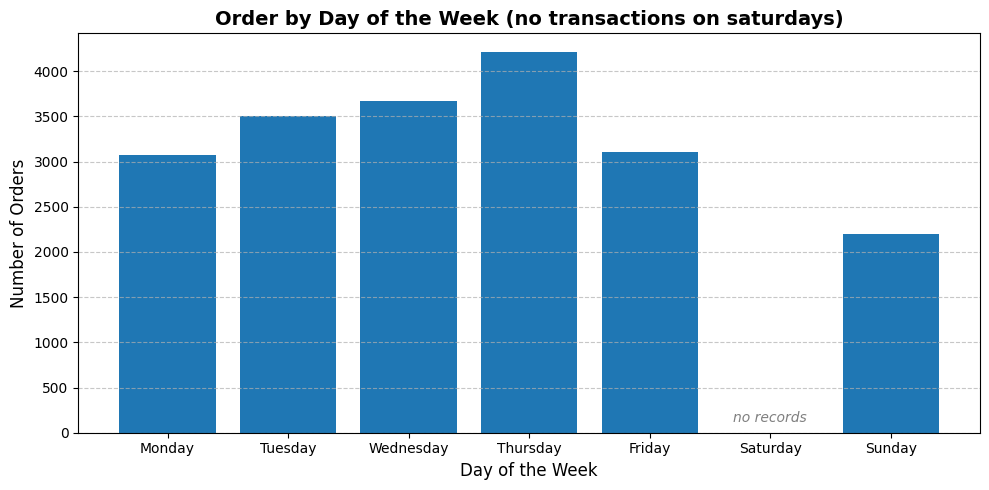

In [16]:
# Fixed weekday order; missing days become NaN
orders_by_day = day_summary['Orders'].reindex(days_order)

# Zero-fill only for drawing; day_summary itself is not modified
plot_values = orders_by_day.fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(days_order, plot_values, color='#1f77b4')

# Make the missing day explicit instead of leaving an unexplained empty slot
saturday_pos = days_order.index('Saturday')
ax.text(saturday_pos, plot_values.max() * 0.02, "no records", ha='center', va='bottom', color='gray', style='italic')

ax.set_title('Order by Day of the Week (no transactions on saturdays)', fontsize=14, fontweight='bold')
ax.set_xlabel('Day of the Week', fontsize=12)
ax.set_ylabel('Number of Orders', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Orders rise from 3,076 on Mondays to a peak of 4,209 on Thursdays (about 21% of all orders), then fall to 3,107 on Fridays. Sundays are the weakest day: 2,203 orders (about 11%), and their average order value (about 362) is roughly 25–35% below the other days (about 486–572), so Sunday orders are both fewer and smaller. No transactions are recorded on Saturdays in either the sales or the returns data, which suggests the business was closed or did not record transactions that day; this cannot be confirmed from the data.

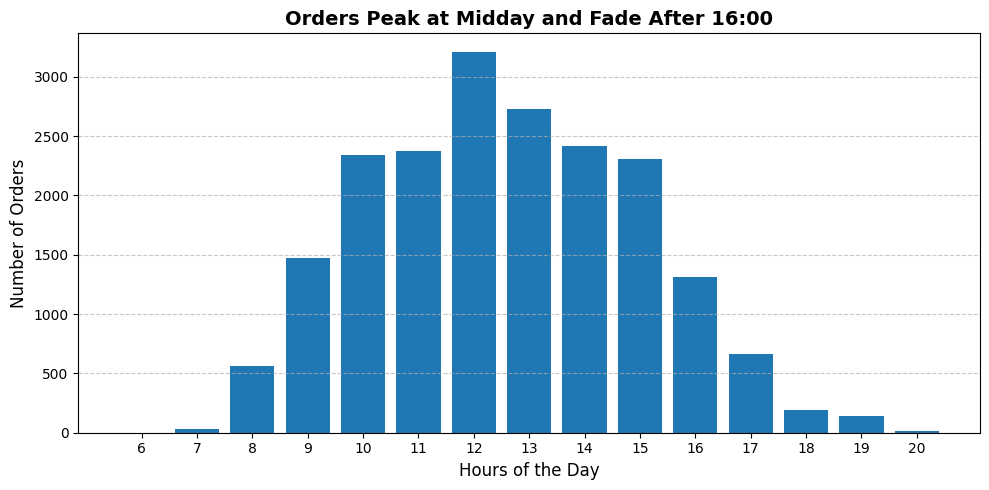

In [17]:
hours = hourly_summary.index.astype(str)

fig ,ax = plt.subplots(figsize=(10, 5))
ax.bar(hours, hourly_summary['Orders'], color='#1f77b4')

ax.set_title('Orders Peak at Midday and Fade After 16:00', fontsize=14, fontweight='bold')
ax.set_xlabel('Hours of the Day', fontsize=12)
ax.set_ylabel('Number of Orders', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Orders are recorded from the 06:00 hour to the 20:00 hour, with a peak at 12:00 (3,205 orders). About 78% of orders fall between 10:00 and 15:59, so activity is concentrated in the middle of the working day. The timestamps have no documented time zone; since about 91% of raw rows come from the UK the times are likely UK local time, but this is not confirmed.

## 2.3 Short summary for a non-technical reader:

 Sales rise sharply in autumn: November revenue (about 1.45M) was roughly double August’s, and this came almost entirely from more orders, not from larger ones. Orders are concentrated midweek (Tuesday to Thursday) and between 10:00 and 15:59 (about 78% of orders), while Sundays are the weakest day, with fewer and smaller orders. These patterns suggest planning staffing, stock, and delivery capacity around the autumn peak and the midweek daytime hours. This is based on a single year of data, so we cannot tell whether the autumn peak repeats every year.

# Phase 3: Products and Countries

## 3.1 Product Contribution

**Business question:** Which products drive revenue, and how concentrated is revenue among them?

- Unit of analysis: `StockCode` (one product). A product's name (`Description`) is used only as a label.
- Metrics: revenue (sum of `TotalPrice`), units sold (sum of `Quantity`), and orders containing the product (distinct `InvoiceNo`).
- The three reversed invoices are excluded, as in Phase 2.

In [18]:
# Create a product summary table based on StockCode
product_summary = sales_filtered.groupby('StockCode').agg(
    description = ('Description','first'),
    revenue = ('TotalPrice', 'sum'),
    units = ('Quantity', 'sum'),
    orders = ('InvoiceNo', 'nunique')
).reset_index()

# create average price and units pre order
product_summary['avg_price'] = (
    product_summary['revenue']
    / product_summary['units'].where(product_summary['units'] != 0)
      )

product_summary['units_per_order'] = (
    product_summary['units'] 
    / product_summary['orders'].where(product_summary['orders'] != 0)
    )

# Sort by descending revenue (form highest to lowest )
product_summary = product_summary.sort_values(by= 'revenue', ascending=False).reset_index(drop=True)

# calculate cumulative share of revenue
product_summary['CumShare'] = product_summary['revenue'].cumsum() / product_summary['revenue'].sum()

# 4. Calculating the number of products required to reach 50% and 80% of revenue
n_50 = (product_summary['CumShare'] < 0.5).sum() + 1
n_80 = (product_summary['CumShare'] < 0.8).sum() + 1

pct_50 = (n_50 / len(product_summary)) * 100
pct_80 = (n_80 / len(product_summary)) * 100


print(f"Total Unique Products: {len(product_summary)}")
print(f"Products needed for 50% revenue: {n_50} ({pct_50:.2f}%)")
print(f"Products needed for 80% revenue: {n_80} ({pct_80:.2f}%)")

# display 10 top products by revenue
print("\nTop 10 Products by Revenue:")
display(product_summary.head(10))


Total Unique Products: 3906
Products needed for 50% revenue: 249 (6.37%)
Products needed for 80% revenue: 844 (21.61%)

Top 10 Products by Revenue:


,StockCode,description,revenue,units,orders,avg_price,units_per_order,CumShare
0,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,12.573572,6.967304,0.017481
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,2198,2.775238,17.125114,0.027967
2,47566,PARTY BUNTING,99445.23,18283,1685,5.439218,10.850445,0.037948
3,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,1.946617,23.155098,0.047400
4,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,2.175413,30.924547,0.054112
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,3.356386,16.662931,0.060624
6,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,1.620582,24.991065,0.066539
7,79321,CHILLI LIGHTS,54096.36,10302,661,5.251054,15.585477,0.071969
8,22197,SMALL POPCORN HOLDER,51334.47,56898,1392,0.902219,40.875000,0.077121
9,23298,SPOTTY BUNTING,43148.18,8466,1146,5.096643,7.387435,0.081452


In [19]:
# top 10 products by units
product_summary.sort_values(by='units', ascending=False).head(10).reset_index(drop=True)

,StockCode,description,revenue,units,orders,avg_price,units_per_order,CumShare
0,22197,SMALL POPCORN HOLDER,51334.47,56898,1392,0.902219,40.875000,0.077121
1,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,535,0.251388,102.712150,0.382196
2,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,1.946617,23.155098,0.047400
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,2198,2.775238,17.125114,0.027967
4,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320,0.583758,27.572727,0.277174
5,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,1.620582,24.991065,0.066539
6,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,2.175413,30.924547,0.054112
7,22492,MINI PAINT SET VINTAGE,16937.82,26633,380,0.635971,70.086842,0.333559
8,22616,PACK OF 12 LONDON TISSUES,7975.98,26119,512,0.305371,51.013672,0.541237
9,21977,PACK OF 60 PINK PAISLEY CAKE CASES,12226.32,24820,869,0.492600,28.561565,0.419746


**Units vs revenue:** Only 5 of the top 10 products by units sold also appear in the top 10 by revenue. Low-priced items such as the World War 2 Gliders (about 0.25 per unit, over 100 units per order) rank second by units but contribute only about 0.14% of revenue, so unit volume is a misleading measure of product importance.

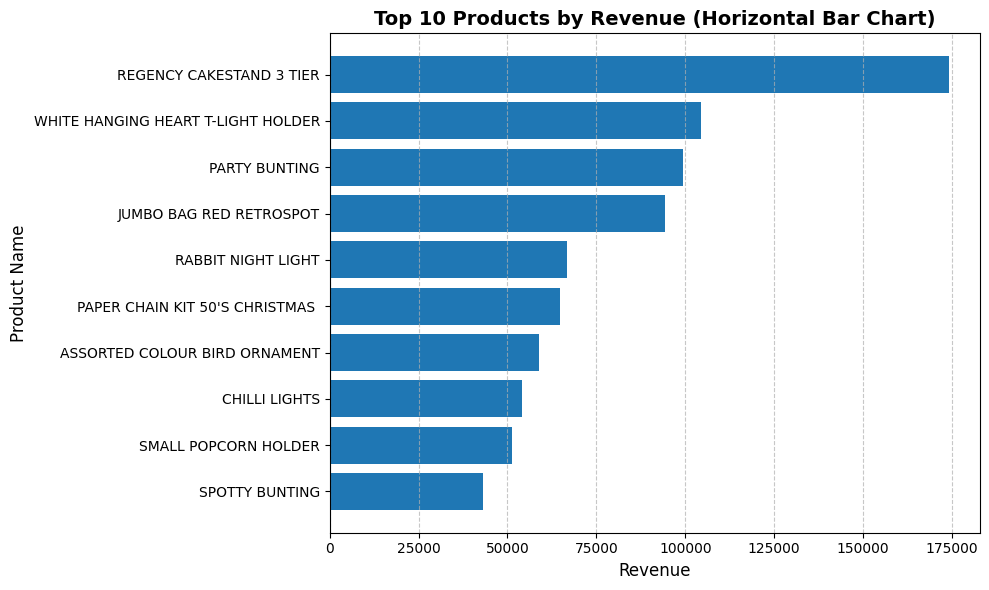

In [20]:
# plot top 10 products by revenue

fig, ax = plt.subplots(figsize=(10, 6))

top_revenue_plot = product_summary.head(10)

ax.barh(top_revenue_plot['description'],
        top_revenue_plot['revenue'], color= '#1f77b4')

ax.set_title('Top 10 Products by Revenue (Horizontal Bar Chart)', fontsize=14, fontweight='bold')
ax.set_xlabel('Revenue', fontsize= 12)
ax.set_ylabel('Product Name', fontsize= 12)
ax.invert_yaxis()
ax.grid(axis='x', linestyle='--', alpha= 0.7)

plt.tight_layout()
plt.show()

**Interpretation:** The Regency Cakestand 3 Tier is the top product at about 174K in revenue (1.7% of total), roughly 1.7 times the runner-up, but the top 10 products together generate only about 811K, or 8.1% of total revenue. No single product dominates the business. The list is mostly party and home-decor items, with one seasonal product (Christmas paper chain kit). Revenue is not profit, and colour variants with separate stock codes are counted as separate products.

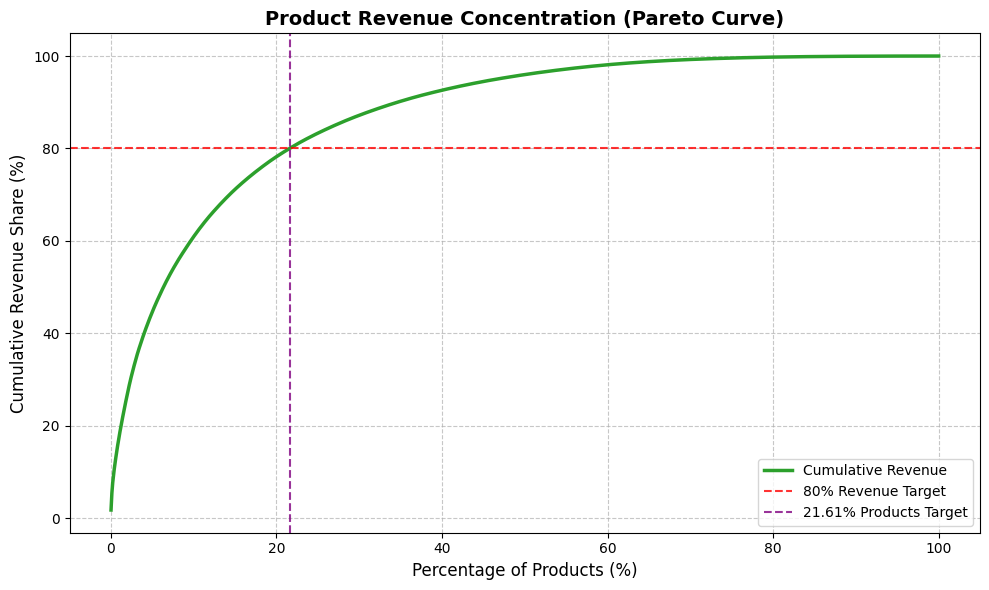

In [21]:
n = len(product_summary)
x = np.arange(1, n + 1) / n * 100
y = product_summary['CumShare'] * 100

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y, color='#2ca02c', linewidth=2.5, label='Cumulative Revenue')


ax.axhline(
    80, color='red', linestyle='--', alpha=0.8, label='80% Revenue Target'
)
ax.axvline(
    21.61,
    color='purple',
    linestyle='--',
    alpha=0.8,
    label='21.61% Products Target',
)

ax.set_title(
    'Product Revenue Concentration (Pareto Curve)',
    fontsize=14,
    fontweight='bold',
)
ax.set_xlabel('Percentage of Products (%)', fontsize=12)
ax.set_ylabel('Cumulative Revenue Share (%)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation:** Revenue is concentrated but not extremely so: 249 products (6.4% of 3,906) account for 50% of revenue, and 844 products (21.6%) account for 80%. The curve flattens after roughly the first 40% of products, so the long tail contributes little individually. This shows how much revenue each group generates, not whether a wide catalogue helps attract customers, so it does not by itself justify dropping low-revenue products. Colour variants with separate stock codes are counted separately, which likely understates concentration.

## 3.2 Sales by Country

**Business question:** How dependent is the business on the UK, and which other countries contribute meaningfully?

- Metrics per country: revenue (sum of `TotalPrice`), orders (distinct `InvoiceNo`), identified customers (distinct `CustomerID`, excluding missing), and AOV.
- The UK dominates, so its share is reported as a single number and the comparison chart covers non-UK countries only.
- The three reversed invoices are excluded; `EIRE` was standardized to `Ireland` in the cleaning step.

In [22]:
# create country summary
country_summary = sales_filtered.groupby('Country').agg(
    revenue=('TotalPrice', 'sum'),
    orders=('InvoiceNo', 'nunique'),
    customers=('CustomerID', 'nunique')
)
# calculate AOV
country_summary['aov']= country_summary['revenue'] / country_summary['orders']

# sort by revenue descending
country_summary = country_summary.sort_values(by= 'revenue', ascending=False)

country_summary.head(10)

,revenue,orders,customers,aov
Country,,,,
United Kingdom,8439820.47,17898,3915,471.551038
Netherlands,283889.34,93,9,3052.573548
Ireland,270850.86,282,3,960.464043
Germany,205381.15,443,94,463.614334
France,184493.00,382,87,482.965969
Australia,138103.81,56,9,2466.139464
Spain,55706.56,88,30,633.029091
Switzerland,53065.60,50,21,1061.312000
Japan,37416.37,19,8,1969.282632


In [23]:
# calculate UK share
uk_revenue = country_summary.loc['United Kingdom', 'revenue'] / country_summary['revenue'].sum()
uk_orders = country_summary.loc['United Kingdom', 'orders'] / country_summary['orders'].sum()
uk_customer = country_summary.loc['United Kingdom', 'customers'] / country_summary['customers'].sum()

print(f"\nUnited Kingdom Share:")
print(f"  Revenue: {uk_revenue:.2%}")
print(f"  Orders: {uk_orders:.2%}")
print(f"  Customers: {uk_customer:.2%}")


United Kingdom Share:
  Revenue: 84.72%
  Orders: 90.53%
  Customers: 90.19%


In [24]:
# top 10 countries excluding UK
top10_excl_uk = country_summary.drop("United Kingdom").head(10)

print("\nTop 10 Countries (excluding UK):")
print(top10_excl_uk)


Top 10 Countries (excluding UK):
               revenue  orders  customers          aov
Country                                               
Netherlands  283889.34      93          9  3052.573548
Ireland      270850.86     282          3   960.464043
Germany      205381.15     443         94   463.614334
France       184493.00     382         87   482.965969
Australia    138103.81      56          9  2466.139464
Spain         55706.56      88         30   633.029091
Switzerland   53065.60      50         21  1061.312000
Japan         37416.37      19          8  1969.282632
Belgium       36927.34      98         25   376.809592
Sweden        36828.83      34          8  1083.200882


In [25]:
# add revenue_per_customer to countries excluding UK
top10_excl_uk['revenue_per_customer'] = top10_excl_uk['revenue'] / top10_excl_uk['customers']

top10_excl_uk

,revenue,orders,customers,aov,revenue_per_customer
Country,,,,,
Netherlands,283889.34,93,9,3052.573548,31543.260000
Ireland,270850.86,282,3,960.464043,90283.620000
Germany,205381.15,443,94,463.614334,2184.905851
France,184493.00,382,87,482.965969,2120.609195
Australia,138103.81,56,9,2466.139464,15344.867778
Spain,55706.56,88,30,633.029091,1856.885333
Switzerland,53065.60,50,21,1061.312000,2526.933333
Japan,37416.37,19,8,1969.282632,4677.046250
Belgium,36927.34,98,25,376.809592,1477.093600


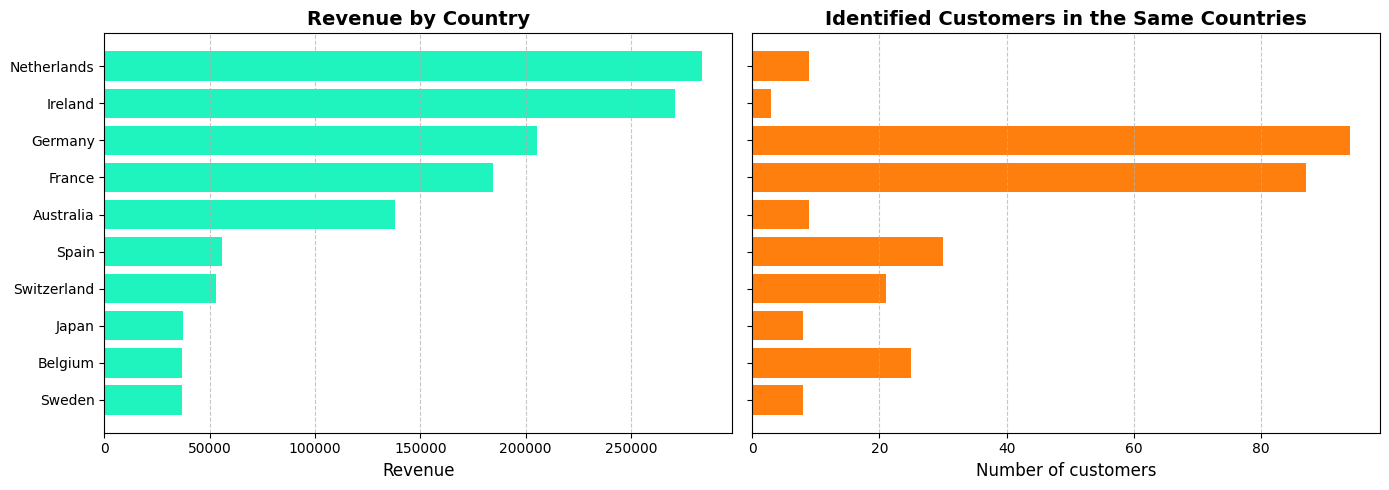

In [26]:
countries = top10_excl_uk.index

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# left panel: revenue
axes[0].barh(countries, top10_excl_uk["revenue"], color="#1ff4bf")
axes[0].set_title("Revenue by Country", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Revenue", fontsize=12)
axes[0].grid(axis="x", linestyle="--", alpha=0.7)

# right panel: customers in the same countries
axes[1].barh(countries, top10_excl_uk["customers"], color="#ff7f0e")
axes[1].set_title("Identified Customers in the Same Countries", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Number of customers", fontsize=12)
axes[1].grid(axis="x", linestyle="--", alpha=0.7)

axes[0].invert_yaxis()   

plt.tight_layout()
plt.show()

**Interpretation:** The UK accounts for 84.7% of revenue, 90.5% of orders and 90.2% of identified customers, so the business depends heavily on its home market. Outside the UK, the Netherlands, Ireland and Australia rank 1st, 2nd and 5th by revenue, but together they rest on only 21 identified customers (9, 3 and 9) and make up about 45% of non-UK revenue; Germany and France, with 94 and 87 customers and revenue per customer close to the UK's (about 2,100–2,200), look like broader and more stable markets. Customer counts exclude orders without a CustomerID (5% of Ireland's revenue, none for the Netherlands or Australia), and 8 customers are recorded under more than one country, so counts are approximate. "Unspecified" and "European Community" are not countries but cover only about 0.1% of rows, and revenue is not profit.

# Phase 4: Customers and Returns

## 4.1 Customer Value Concentration

**Business question:** How concentrated is revenue among identified customers, and how do the highest value customers buy?

- Unit of analysis: `CustomerID`. Rows with a missing `CustomerID` (about 25% of rows) are excluded, since they cannot be tied to a customer.
- Metrics per customer: revenue, orders (distinct `InvoiceNo`), first and last purchase date.
- The three reversed invoices are excluded, as in earlier phases.
- Revenue is not profit, so "high-value" means high revenue.

In [27]:
# create customer summary tabel
customer_summary = sales_filtered.groupby('CustomerID').agg(
    revenue=('TotalPrice', 'sum'),
    orders=('InvoiceNo', 'nunique'),
    first_purchase=('InvoiceDate', 'min'),
    last_purchase=('InvoiceDate', 'max')
).reset_index()

# Calculate Average Order Value
customer_summary['aov'] = customer_summary['revenue'] / customer_summary['orders']

# Sort by revenue in descending order
customer_summary = customer_summary.sort_values('revenue', ascending=False).reset_index(drop=True)

# Calculate Cumulative Share of customer revenue
customer_summary['CumShare'] = customer_summary['revenue'].cumsum() / customer_summary['revenue'].sum()

# Top 1%, 10% and 20% share
n = len(customer_summary)
total = customer_summary["revenue"].sum()

for pct in [0.01, 0.10, 0.20]:
    k = int(pct * n)                                 
    share = customer_summary["revenue"].head(k).sum() / total
    print(f"Top {pct:.0%} ({k} customers): {share:.1%} of identified revenue")

# Number of customers needed for 50% and 80% revenue
for target in [0.5, 0.8]:
    k = (customer_summary["CumShare"] < target).sum() + 1
    print(f"{k} customers ({k / n:.1%} of all) reach {target:.0%} of revenue")


# Median orders for top 10% and bottom 90%
k = int(0.10 * n)
top = customer_summary.head(k)       # top 10% by revenue
rest = customer_summary.iloc[k:]     # the other 90%

print("Median orders: top 10% =", top["orders"].median(), "| rest =", rest["orders"].median())
print("Median AOV:    top 10% =", round(top["aov"].median(), 1), "| rest =", round(rest["aov"].median(), 1))

Top 1% (43 customers): 30.3% of identified revenue
Top 10% (433 customers): 60.2% of identified revenue
Top 20% (866 customers): 73.8% of identified revenue
233 customers (5.4% of all) reach 50% of revenue
1167 customers (26.9% of all) reach 80% of revenue
Median orders: top 10% = 12.0 | rest = 2.0
Median AOV:    top 10% = 520.5 | rest = 264.8


In [28]:
# table of top 10 customers with country
top_10 = customer_summary.head(10).copy()
country_of = sales_filtered.groupby('CustomerID')['Country'].first()
top_10['country'] = top_10['CustomerID'].map(country_of)
top_10[['revenue', 'orders', 'aov', 'country']]

,revenue,orders,aov,country
0,279138.02,72,3876.916944,Netherlands
1,259657.30,60,4327.621667,United Kingdom
2,194390.79,46,4225.886739,United Kingdom
3,136161.83,198,687.686010,Ireland
4,124564.53,20,6228.226500,Australia
5,116560.08,54,2158.520000,Ireland
6,91062.38,31,2937.496129,United Kingdom
7,72708.09,62,1172.711129,United Kingdom
8,66653.56,28,2380.484286,United Kingdom
9,65039.62,50,1300.792400,United Kingdom


**Interpretation:** The 10 highest-value customers (about 0.2% of identified customers) generate roughly 1.41M, or about 14% of total revenue. Four of them are outside the UK although non-UK customers are only about 10% of the base: a single Dutch customer accounts for 98% of the Netherlands' revenue, one Australian customer for 90% of Australia's, and two Irish customers for 93% of Ireland's. Their buying patterns differ (one Irish customer placed 198 orders of about 690 each, the Australian customer 20 orders of about 6,200), so "top customer" does not imply a single behaviour. The data does not say what type of customers these are, so we cannot confirm they are wholesale accounts.

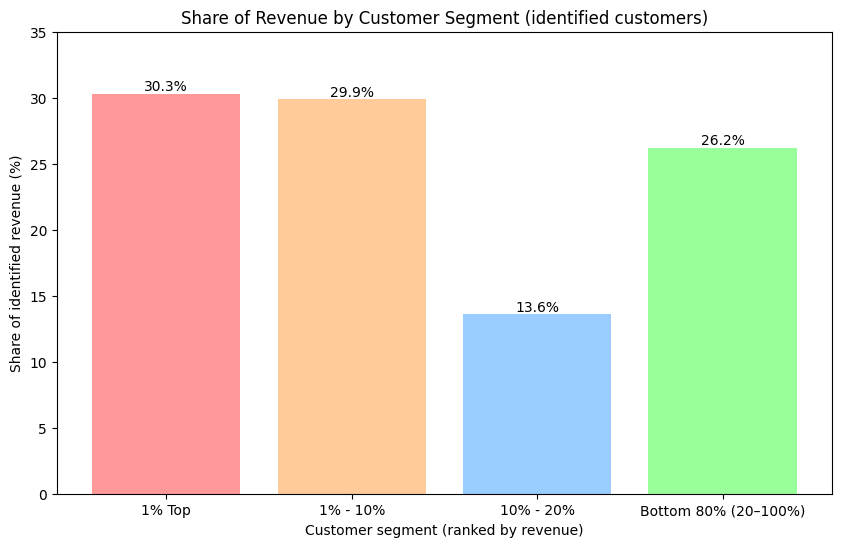

In [29]:
categories = ['1% Top', '1% - 10%', '10% - 20%', 'Bottom 80% (20–100%)']
percentages = [30.3, 29.9, 13.6, 26.2]

plt.figure(figsize=(10, 6))
bars = plt.bar(categories, percentages, color=['#ff9999', '#ffcc99', '#99ccff', '#99ff99'])

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height,
             f'{height:.1f}%', va='bottom', ha='center')

plt.title('Share of Revenue by Customer Segment (identified customers)')
plt.xlabel('Customer segment (ranked by revenue)')
plt.ylabel('Share of identified revenue (%)')
plt.ylim(0, 35)
plt.show()

**Interpretation:** Revenue from identified customers is highly concentrated: the top 1% of customers (43) generate 30.3% of it and the top 10% (433) generate 60.2%, while the bottom 80% together contribute 26.2%. The top 10% buy far more often (median 12 orders versus 2) and also place somewhat larger orders (median AOV about 520 versus 265), so the difference comes more from purchase frequency than from order size; however, since this group was selected by revenue, both measures are expected to be higher in it. Percentages are based on identified customers only (about 85% of total revenue), and the data covers a single year.

In [30]:
last_date = sales_filtered["InvoiceDate"].max()
top_10["days_since_last_purchase"] = (last_date - top_10["last_purchase"]).dt.days
top_10[["country", "orders", "last_purchase", "days_since_last_purchase"]]

,country,orders,last_purchase,days_since_last_purchase
0,Netherlands,72,2011-12-08 12:12:00,1
1,United Kingdom,60,2011-12-09 11:50:00,0
2,United Kingdom,46,2011-12-01 13:29:00,7
3,Ireland,198,2011-12-08 15:54:00,0
4,Australia,20,2011-11-15 14:22:00,23
5,Ireland,54,2011-11-30 10:54:00,9
6,United Kingdom,31,2011-12-07 10:12:00,2
7,United Kingdom,62,2011-11-01 10:27:00,38
8,United Kingdom,28,2011-12-05 14:06:00,3
9,United Kingdom,50,2011-12-06 09:32:00,3


**Recency check:** All 10 top customers made a purchase in the last 38 days of the data, and 9 of them in the last 23 days; six bought within the final 3 days. One UK customer (62 orders) had not bought for 38 days, which is long compared with an average of roughly one order every 6 days if active all year, so this account is worth watching. This is a weak signal only: the data ends on 2011-12-09, so it cannot show whether any customer later stopped buying, and a single year does not reveal each customer's normal purchase rhythm.

## 4.2 New vs Returning Customers

**Business question:** Did the autumn surge come from newly acquired customers or from existing customers ordering more? And how many customers buy only once?

- A customer is **new** in a month if their first purchase in the data falls in that month, and **returning** in any later month.
- Only identified customers (`CustomerID` present) can be classified; rows without an ID are excluded.
- Because the data starts on 2010-12-01, every customer active in December 2010 looks "new" by construction, so that month is not a valid baseline.
- Customers whose first purchase is late in the data had little time to buy again, so the one-time-buyer share is likely overstated.

In [31]:
# set_index returns a new table, so assign it back
customer_summary = customer_summary.set_index("CustomerID")

# keep only rows with a known customer
known = sales_filtered[sales_filtered["CustomerID"].notna()].copy()

# first purchase month of each customer, mapped onto every row
first_month = known["CustomerID"].map(customer_summary["first_purchase"]).dt.to_period("M")

# new = invoice month equals the customer's first-purchase month
known["CustomerType"] = np.where(known["Month"] == first_month, "new", "returning")

In [32]:
print(first_month.isna().sum())                                                   
print(known.loc[known["CustomerType"] == "new", "CustomerID"].nunique())          
print(known.loc[known["Month"] == "2010-12", "CustomerType"].value_counts())     

0
4333
CustomerType
new    25569
Name: count, dtype: int64


In [33]:
monthly_type = known.groupby(["Month", "CustomerType"]).agg(
    customers=('CustomerID', 'nunique'), 
    orders=('InvoiceNo', 'nunique'),    
    revenue=('TotalPrice', 'sum'),     
).unstack("CustomerType")

monthly_type = monthly_type.fillna(0)   # December 2010 has no returning customers

In [34]:
monthly_type

customers            orders              revenue            
CustomerType       new returning     new returning        new   returning
Month                                                                    
2010-12          884.0       0.0  1394.0       0.0  565199.56        0.00
2011-01          415.0     323.0   467.0     515.0  211849.69   273649.62
2011-02          380.0     377.0   420.0     572.0  157250.05   285043.54
2011-03          452.0     521.0   498.0     814.0  196766.83   386377.02
2011-04          300.0     553.0   337.0     802.0  119956.15   334484.73
2011-05          284.0     770.0   322.0    1222.0  118577.90   540664.59
2011-06          242.0     748.0   268.0    1121.0   94618.03   519676.89
2011-07          187.0     759.0   211.0    1110.0   72399.78   519204.01
2011-08          169.0     764.0   182.0    1085.0   78467.02   557047.36
2011-09          299.0     960.0   334.0    1405.0  151709.77   787042.86
2011-10          357.0    1004.0   418.0    1485.0  162056.38   840270.18
2011-11          323.0    1337.0   395.0    2247.0  133595.54  1002938.46
2011-12           41.0     572.0    43.0     732.0   26658.46   317100.02

In [35]:
# Percentage of customers who placed only one order
one_time_customer_share = (customer_summary["orders"] == 1).mean()

print(f"Share of one time customers out of total customers: {one_time_customer_share * 100:.2f}%")

Share of one time customers out of total customers: 34.73%


In [36]:
# 1. Create a mask for one-time customers
one_time_mask = customer_summary["orders"] == 1

# 2. Sum the revenue of this group
revenue_from_one_time = customer_summary.loc[one_time_mask, "revenue"].sum()

# 3. Sum the total revenue of all customers
total_revenue = customer_summary["revenue"].sum()

# 4. Calculate the revenue share percentage
one_time_revenue_share = revenue_from_one_time / total_revenue

print(f"Revenue share of one-time customers out of total revenue: {one_time_revenue_share * 100:.2f}%")

Revenue share of one-time customers out of total revenue: 6.50%


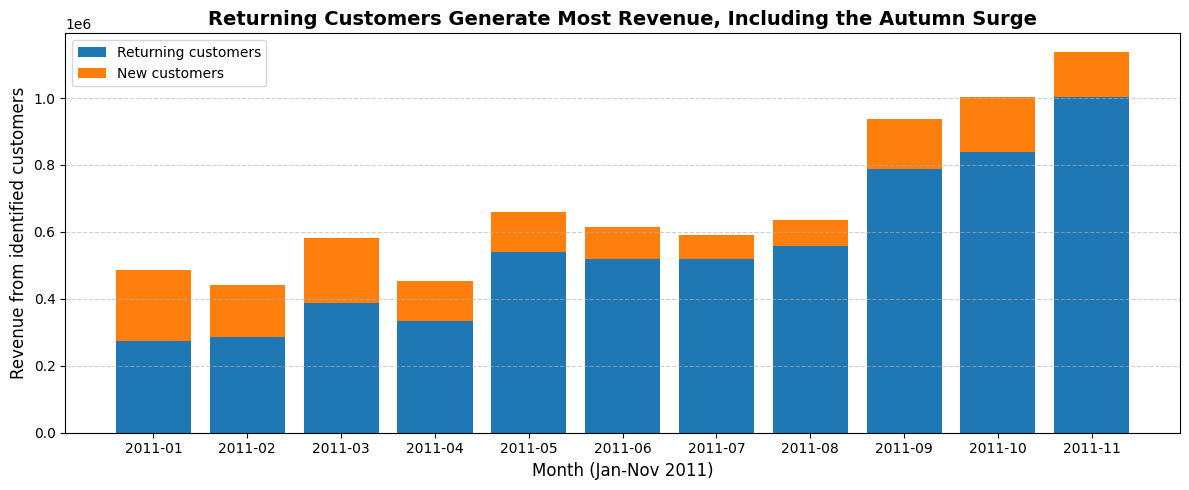

In [37]:
# Drop Dec 2010 (everyone is "new" by construction) and Dec 2011 (partial month)
rev = monthly_type["revenue"].loc["2011-01":"2011-11"]
months = rev.index.astype(str)          # Period -> string, so matplotlib can label the axis

fig, ax = plt.subplots(figsize=(12, 5))

# Bottom layer: returning customers
ax.bar(months, rev["returning"], label="Returning customers", color="#1f77b4")

# Top layer: new customers start where the returning bar ends
ax.bar(months, rev["new"], bottom=rev["returning"], label="New customers", color="#ff7f0e")

ax.set_title("Returning Customers Generate Most Revenue, Including the Autumn Surge",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Month (Jan-Nov 2011)", fontsize=12)
ax.set_ylabel("Revenue from identified customers", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

In [38]:
early = customer_summary[customer_summary["first_purchase"] < "2011-04-01"]
late  = customer_summary[customer_summary["first_purchase"] >= "2011-04-01"]

for name, group in [("early (first purchase before Apr 2011)", early),
                    ("late (first purchase from Apr 2011)", late)]:
    print(f"{name}: {len(group)} customers, {(group['orders'] == 1).mean():.1%} bought once")

early (first purchase before Apr 2011): 2131 customers, 18.9% bought once
late (first purchase from Apr 2011): 2202 customers, 50.1% bought once


**Interpretation:** Customers who bought only once make up 34.7% of identified customers but only 6.5% of revenue, so one-time buyers matter little for revenue. The 34.7% is an upper bound: customers who first bought before April 2011 had at least eight months to return and only 18.9% bought once, versus 50.1% for later customers who had less time (although the early group also includes some pre-existing customers, which pushes its figure down slightly). Of the roughly 501K rise in identified-customer revenue from August to November, about 89% (446K) came from returning customers, because many more of them were active (764 to 1,337) while revenue per active returning customer barely changed (about 730 to 750). New-customer revenue follows a U shape (from about 212K in January to 72K in July, then back to 162K in October), but the early decline is partly an artefact of the data starting in December 2010, so only the September-October rise is reliable. The "returning" share also grows mechanically as the customer base accumulates, and all figures cover identified customers only.

## 4.3 Cancellations and Returns

**Business question:** How large are product cancellations relative to sales, and which products are cancelled most often?

- Scope: only `product_cancellation` rows (invoices starting with "C" on genuine product codes). Non-product cancellations (fees, manual entries, postage) and stock adjustments are excluded.
- Two cancellation invoices (C581484 and C541433) that reverse orders cancelled within minutes are excluded, as in earlier sections.
- Cancellations are not matched to their original orders, so a cancellation may relate to a sale outside the period or in a different month.
- A cancellation is not proof that goods were physically returned.

In [39]:
# The two cancellation invoices that reverse mistaken orders (see Phase 1 audit)
REVERSAL_INVOICES = ["C581484", "C541433"]

prod_ret = returns[(returns["ReturnType"] == "product_cancellation")
                   & (~returns["InvoiceNo"].isin(REVERSAL_INVOICES))]

In [40]:
# Calculate cancellation rates
value_rate = -prod_ret["TotalPrice"].sum() / sales_filtered["TotalPrice"].sum()
invoice_rate = prod_ret["InvoiceNo"].nunique() / sales_filtered["InvoiceNo"].nunique()

print(f"Value-based cancellation rate: {value_rate:.2%}")
print(f"Invoice-based cancellation rate: {invoice_rate:.2%}")

Value-based cancellation rate: 2.31%
Invoice-based cancellation rate: 17.30%


In [41]:
# Units returned per product (Quantity is negative in returns, so flip the sign)
returned = (-prod_ret.groupby("StockCode")["Quantity"].sum()).rename("units_returned")

# Units sold and number of orders per product
sold = sales_filtered.groupby("StockCode").agg(
    units_sold=("Quantity", "sum"),
    orders=("InvoiceNo", "nunique"),
)

product_returns = sold.join(returned)                       # keeps every sold product
product_returns["units_returned"] = product_returns["units_returned"].fillna(0)
product_returns["return_rate"] = product_returns["units_returned"] / product_returns["units_sold"]

In [42]:
# Only products with enough orders for the rate to be meaningful
reliable = product_returns[product_returns["orders"] >= 200]
print(len(product_returns), "products ->", len(reliable), "reliable")

3906 products -> 812 reliable


In [43]:
# StockCode -> description lookup (check the column name in your product_summary)
desc = product_summary.set_index("StockCode")["description"]

top_rate = reliable.nlargest(10, "return_rate").copy()
top_rate["description"] = top_rate.index.map(desc)

print("Missing descriptions:", top_rate["description"].isna().sum())   # expect 0
top_rate[["description", "orders", "units_sold", "units_returned", "return_rate"]]

Missing descriptions: 0


,description,orders,units_sold,units_returned,return_rate
StockCode,,,,,
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,449,9461,9376.0,0.991016
47566B,TEA TIME PARTY BUNTING,365,2379,1424.0,0.598571
22920,HERB MARKER BASIL,242,3423,1527.0,0.446100
22273,FELTCRAFT DOLL MOLLY,331,4509,1447.0,0.320914
21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,262,10241,3150.0,0.307587
20733,GOLD MINI TAPE MEASURE,205,1234,300.0,0.243112
22191,IVORY DINER WALL CLOCK,415,1445,344.0,0.238062
21877,HOME SWEET HOME MUG,349,5411,1052.0,0.194419
48185,DOORMAT FAIRY CAKE,365,3615,674.0,0.186445


In [44]:
top_revenue_codes = set(product_summary.nlargest(10, "revenue")["StockCode"])
overlap = set(top_rate.index) & top_revenue_codes
print(len(overlap), "of 10 overlap:", overlap)

0 of 10 overlap: set()


In [45]:
overall_rate = product_returns["units_returned"].sum() / product_returns["units_sold"].sum()
median_reliable = reliable["return_rate"].median()
top_rev_rates = product_returns.loc[list(top_revenue_codes), "return_rate"]

print(f"Overall unit return rate: {overall_rate:.2%}")
print(f"Median rate, reliable products: {median_reliable:.2%}")
print(f"Median rate, top-10 revenue products: {top_rev_rates.median():.2%}")

Overall unit return rate: 2.12%
Median rate, reliable products: 0.86%
Median rate, top-10 revenue products: 1.41%


In [46]:
codes = list(top_rate.index[:5])
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "CustomerID", "InvoiceDate"]
prod_ret[prod_ret["StockCode"].isin(codes)].nsmallest(8, "Quantity")[cols]

,InvoiceNo,StockCode,Description,Quantity,CustomerID,InvoiceDate
33,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,15838,2010-12-02 14:23:00
3032,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,15749,2011-04-18 13:08:00
4159,C556522,22920,HERB MARKER BASIL,-1515,16938,2011-06-13 11:21:00
3029,C550456,47566B,TEA TIME PARTY BUNTING,-1300,15749,2011-04-18 13:08:00
7383,C570556,22273,FELTCRAFT DOLL MOLLY,-720,16029,2011-10-11 11:10:00
7388,C570556,22273,FELTCRAFT DOLL MOLLY,-720,16029,2011-10-11 11:10:00
885,C540417,47566B,TEA TIME PARTY BUNTING,-50,13680,2011-01-07 10:56:00
2145,C546191,47566B,TEA TIME PARTY BUNTING,-35,16422,2011-03-10 10:57:00


In [47]:
top_rate["units_returned"].sum() / product_returns["units_returned"].sum()

np.float64(0.17435557801906687)

In [48]:
# Check A: how much of all returned units come from a few very large lines?
bulk = prod_ret["Quantity"] <= -700
share = -prod_ret.loc[bulk, "Quantity"].sum() / -prod_ret["Quantity"].sum()
print(f"{bulk.sum()} of {len(prod_ret):,} lines carry {share:.1%} of returned units")

16 of 8,666 lines carry 24.4% of returned units


In [49]:
# Check B: for each big cancellation line, find a sale with the same customer, product and quantity
big = prod_ret[bulk].copy()
big["SaleQty"] = -big["Quantity"]

m = big.merge(
    sales_filtered[["CustomerID", "StockCode", "Quantity", "InvoiceNo", "InvoiceDate"]],
    left_on=["CustomerID", "StockCode", "SaleQty"],
    right_on=["CustomerID", "StockCode", "Quantity"],
    suffixes=("_cancel", "_sale"),
)
m["days_between"] = (m["InvoiceDate_cancel"] - m["InvoiceDate_sale"]).dt.days
print(f"{len(big)} big cancellation lines, {len(m)} matched to an exact sale")
m[["StockCode", "CustomerID", "SaleQty", "InvoiceNo_sale", "InvoiceNo_cancel", "days_between"]]

16 big cancellation lines, 24 matched to an exact sale


,StockCode,CustomerID,SaleQty,InvoiceNo_sale,InvoiceNo_cancel,days_between
0,85123A,15749,1930,540815,C550456,97
1,85123A,15749,1930,550461,C550456,-1
2,21175,15749,2000,540815,C550456,97
3,21175,15749,2000,550461,C550456,-1
4,21108,15749,3114,540815,C550456,97
5,21108,15749,3114,550461,C550456,-1
6,22920,16938,1515,556484,C556522,0
7,21877,17949,828,558523,C563577,48
8,21069,17949,701,558523,C563577,48
9,23113,17450,756,567423,C567527,0


In [50]:
big_value = -prod_ret.loc[bulk, "TotalPrice"].sum()
total_value = -prod_ret["TotalPrice"].sum()
sales_total = sales_filtered["TotalPrice"].sum()

print(f"16 big lines = {big_value / total_value:.1%} of cancelled value")
print(f"Value cancellation rate: all lines {total_value / sales_total:.2%}, "
      f"without the 16 big lines {(total_value - big_value) / sales_total:.2%}")

16 big lines = 13.7% of cancelled value
Value cancellation rate: all lines 2.31%, without the 16 big lines 1.99%


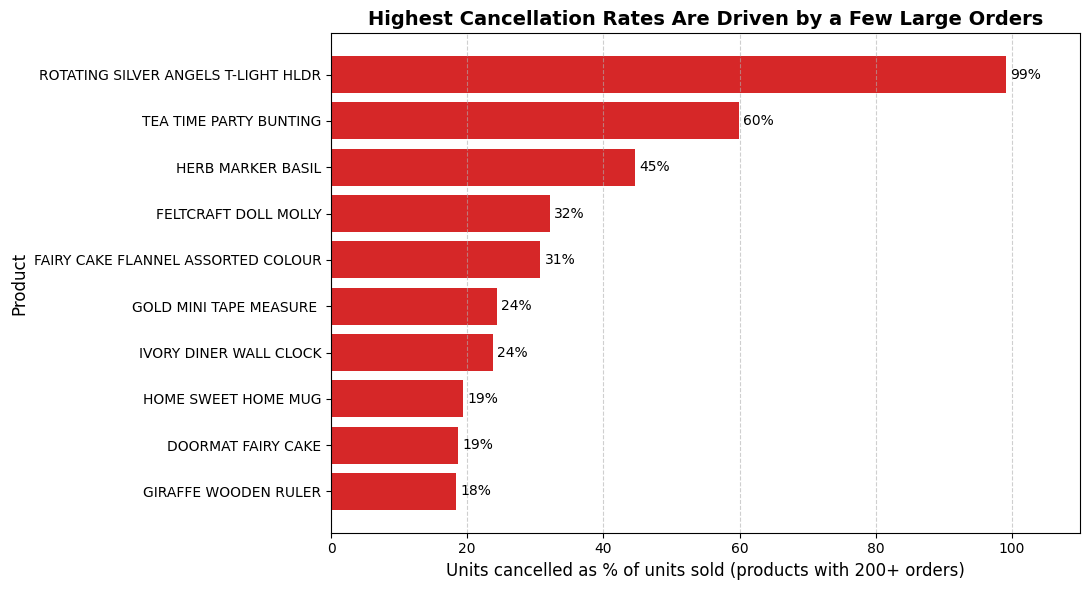

In [51]:
# top_rate is already sorted from the highest rate down (built with nlargest)
labels = top_rate["description"]
rates = top_rate["return_rate"] * 100          # fraction -> percent

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(labels, rates, color="#d62728")

# Print the percentage at the end of each bar
ax.bar_label(bars, fmt="%.0f%%", padding=3)

ax.invert_yaxis()                               # highest rate on top
ax.set_title("Highest Cancellation Rates Are Driven by a Few Large Orders",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Units cancelled as % of units sold (products with 200+ orders)", fontsize=12)
ax.set_ylabel("Product", fontsize=12)
ax.set_xlim(0, 110)                             # room for the labels at the end of the bars
ax.grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Interpretation:** Product cancellations are small relative to sales: about 2.3% of revenue by value (1.99% if 16 unusually large lines are excluded) and 2.1% of units, although the number of cancellation invoices equals 17.3% of the number of sales invoices, so cancellations are frequent but usually small. The products with the highest cancellation rates (for example 84347 at 99%) are not a reliable quality signal: 16 large lines (0.2% of cancellation lines) carry 24% of all cancelled units and 13.7% of cancelled value, and for 13 of them the same customer had a sale of exactly the same product and quantity, in 11 cases within about three days of the cancellation (before or after). This looks more like corrected orders than customer returns. None of the ten highest-rate products is in the top ten by revenue, and a typical product with 200+ orders has a cancellation rate below 1%. Cancellations are not linked to original orders and do not prove that goods were returned.